# توقّع أسعار المنازل – House Prices (Regression)

**الفكرة:** نبني نموذجاً يتنبأ بـ `SalePrice`، ونطبّق **Feature Selection على الأعمدة الأصلية الـ79** *داخل* الـ Pipeline وقبل `OneHotEncoder`، بحيث يُعاد الاختيار في **كل Fold** من الـ Cross Validation دون أن يرى النموذج بيانات التحقق أو الاختبار.

**خطوات المشروع**
1. تحميل البيانات واستكشافها
2. تجهيز الأعمدة وتقسيم البيانات (Train / Test)
3. كتابة `OriginalFeatureSelector` (Custom Transformer)
4. بناء الـ Pipeline
5. التأكد من إعادة الاختيار داخل كل Fold
6. مقارنة: كل الأعمدة (All 79) مقابل نسب أهمية 70% / 80% / 90% / 95% / 99%
7. اختيار أقل مجموعة أعمدة بأداء قريب من الأفضل (بالـ CV فقط)
8. تحسين النموذج بـ `GridSearchCV`
9. التقييم النهائي على Test Set (مرة واحدة فقط)
10. فحوصات التدقيق (Double Log، Leakage، المقاييس)
11. الأعمدة المختارة والمستبعدة
12. حفظ النموذج وإعادة تحميله

## 0) استيراد المكتبات والإعدادات

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42   # رقم ثابت لتكون النتائج قابلة للتكرار

# ---- التوازي (Parallelism) ----
# على Windows يسبب n_jobs=-1 أحياناً الخطأ: OSError: [Errno 22] Invalid argument
# لذلك نشغّل كل شيء تسلسلياً (عملية واحدة). هذا أبطأ لكنه مستقر.
# n_jobs يُمرَّر لـ cross_validate و GridSearchCV و RandomForest، ولا يوجد توازٍ متداخل.
N_JOBS = 1
PRE_DISPATCH = 1    # لا نُحمِّل مهام مسبقاً في طابور التنفيذ

## 1) تحميل البيانات واستكشافها

In [2]:
df = pd.read_csv('train.csv')
print('الشكل (صفوف، أعمدة):', df.shape)
df.head()

الشكل (صفوف، أعمدة): (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print('إحصائيات السعر SalePrice:')
print(df['SalePrice'].describe())

# الانحراف (Skewness): كلما اقترب من 0 كان التوزيع أقرب للمتماثل
print('\nالانحراف قبل log:', round(df['SalePrice'].skew(), 2))
print('الانحراف بعد log:', round(np.log1p(df['SalePrice']).skew(), 2))

missing = df.isnull().sum()
print('\nأكثر الأعمدة التي فيها قيم مفقودة:')
print(missing[missing > 0].sort_values(ascending=False).head(10))

إحصائيات السعر SalePrice:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

الانحراف قبل log: 1.88
الانحراف بعد log: 0.12

أكثر الأعمدة التي فيها قيم مفقودة:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
dtype: int64


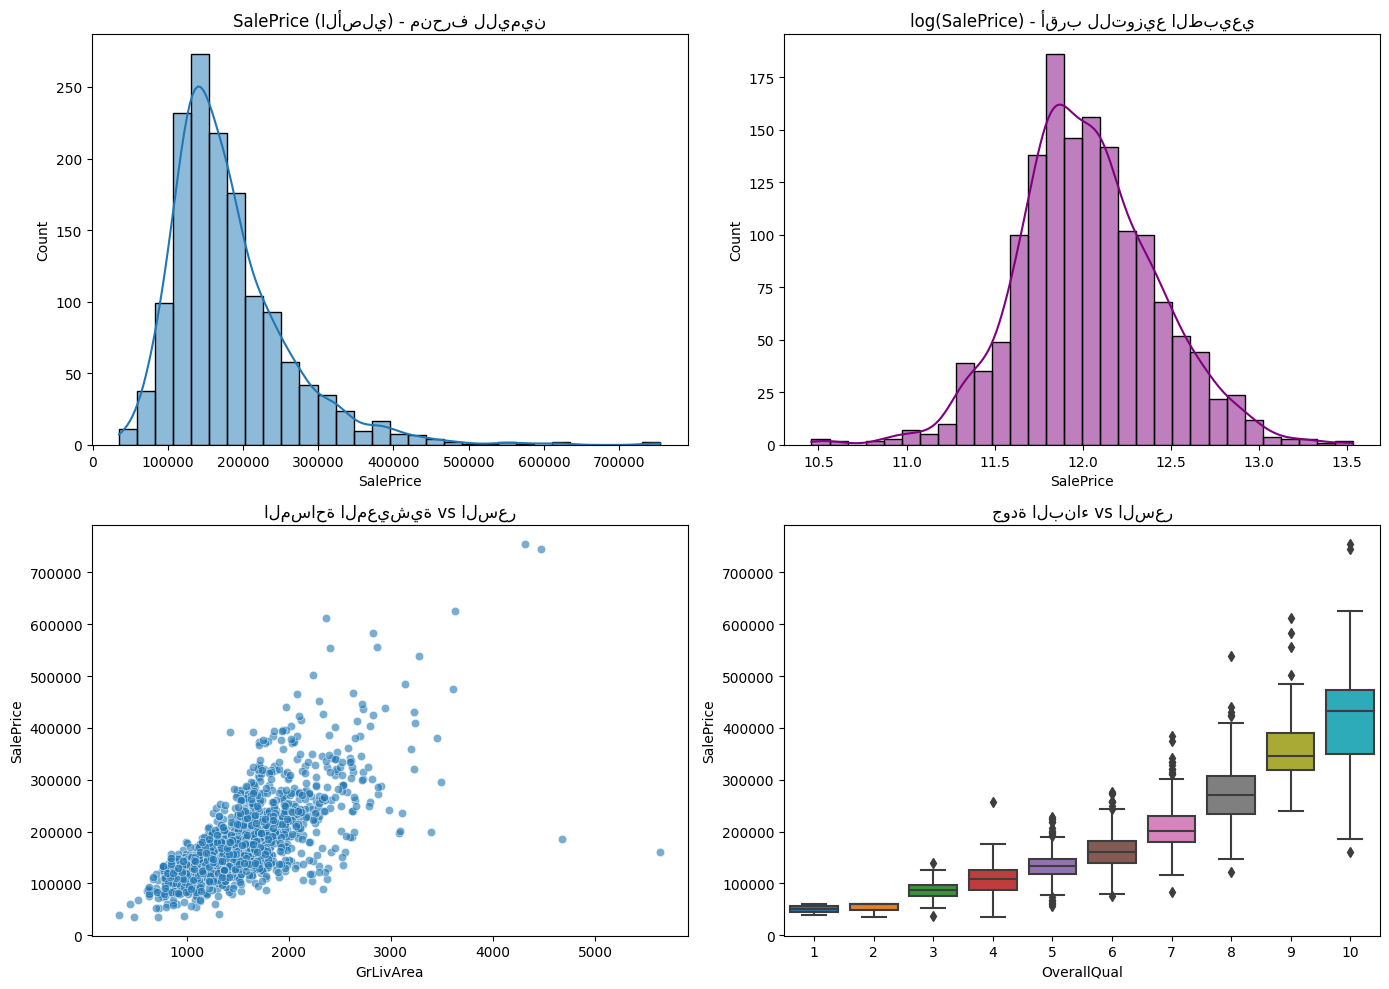

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['SalePrice'], kde=True, bins=30, ax=axes[0, 0])
axes[0, 0].set_title('SalePrice (الأصلي) - منحرف لليمين')

sns.histplot(np.log1p(df['SalePrice']), kde=True, bins=30, color='purple', ax=axes[0, 1])
axes[0, 1].set_title('log(SalePrice) - أقرب للتوزيع الطبيعي')

sns.scatterplot(x='GrLivArea', y='SalePrice', data=df, alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title('المساحة المعيشية vs السعر')

sns.boxplot(x='OverallQual', y='SalePrice', data=df, ax=axes[1, 1])
axes[1, 1].set_title('جودة البناء vs السعر')

plt.tight_layout()
plt.show()

## 2) تجهيز الأعمدة وتقسيم البيانات

- نحذف `Id` (مجرد رقم تعريفي) و`SalePrice` (الهدف) ⇒ يبقى **79 عموداً أصلياً**.
- `MSSubClass` و`MoSold` أرقام لكنها في الحقيقة **فئات** (نوع المبنى / رقم الشهر)، لذلك نحوّلها إلى نص. هذا مجرد تصحيح لنوع العمود ولا يتعلّم أي شيء من البيانات، فلا يسبب Data Leakage.
- القيم المفقودة في الأعمدة النصية غالباً تعني "غير موجود" (مثل: لا يوجد قبو أو مسبح)، لذلك سنملؤها بكلمة `Missing`.
- **نعزل Test Set الآن ولا نستخدمه إلا في الخطوة الأخيرة.**

In [5]:
X = df.drop(columns=['SalePrice', 'Id'])   # الأعمدة الأصلية (الميزات)
y = df['SalePrice']                         # الهدف

# أعمدة رقمية لكنها فئات -> نحولها إلى نص
X['MSSubClass'] = X['MSSubClass'].astype(str)
X['MoSold'] = X['MoSold'].astype(str)

n_numeric = X.select_dtypes(include='number').shape[1]
n_categorical = X.shape[1] - n_numeric
print(f'عدد الأعمدة الأصلية: {X.shape[1]} (رقمية: {n_numeric}، فئوية: {n_categorical})')

# تقسيم 80% تدريب / 20% اختبار
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test (محجوز):', X_test.shape)

عدد الأعمدة الأصلية: 79 (رقمية: 34، فئوية: 45)
Train: (1168, 79) | Test (محجوز): (292, 79)


## 3) الـ Custom Transformer: `OriginalFeatureSelector`

يختار من **الأعمدة الأصلية** (وليس من الأعمدة الناتجة عن One-Hot). كيف يعمل داخل `fit`؟
1. يجهّز نسخة مؤقتة من بيانات التدريب: يملأ المفقودات، ويحوّل الأعمدة الفئوية إلى أعمدة 0/1 (Dummies).
2. يدرّب `RandomForest` ليحسب أهمية كل عمود.
3. **يجمع أهمية الـ Dummies التابعة لنفس العمود الأصلي** (مثلاً كل أعمدة `Neighborhood_...` تُجمع في أهمية واحدة لـ`Neighborhood`).
4. يرتّب الأعمدة الأصلية من الأهم إلى الأقل أهمية، ويحتفظ بالأعمدة الأولى حتى تصل **أهميتها التراكمية** إلى `importance_threshold` (مثلاً 0.95 = 95% من إجمالي الأهمية).
   - **القيمة `1.0` تعني الاحتفاظ بكل الأعمدة الـ79 فعلياً** (بدون أي اختيار).

الدالة `transform` تُرجع فقط الأعمدة المختارة. وبما أن `fit` يُستدعى على بيانات التدريب فقط، لا يوجد تسرّب من بيانات التحقق/الاختبار.
> `y` الذي يصل إلى هذا المُحدِّد هو **log(السعر)** لأن `TransformedTargetRegressor` يحوّله قبل تمريره للـ Pipeline، لذلك لا نطبّق log مرة ثانية داخل المُحدِّد.

In [6]:
class OriginalFeatureSelector(BaseEstimator, TransformerMixin):
    """يختار الأعمدة الأصلية الأهم اعتماداً على أهمية Random Forest التراكمية."""

    def __init__(self, importance_threshold=0.95, n_estimators=50, random_state=42):
        self.importance_threshold = importance_threshold  # نسبة الأهمية التراكمية المطلوب الاحتفاظ بها
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y):
        # (1) نفصل الأعمدة الرقمية عن الفئوية
        numeric_cols = X.select_dtypes(include='number').columns.tolist()
        categorical_cols = [c for c in X.columns if c not in numeric_cols]

        # (2) نجهّز نسخة مؤقتة: نملأ المفقودات ونحوّل الفئات إلى Dummies
        parts = [X[numeric_cols].fillna(X[numeric_cols].median())]
        owner = list(numeric_cols)  # owner[i] = اسم العمود الأصلي الذي جاء منه العمود i
        for col in categorical_cols:
            dummies = pd.get_dummies(X[col].fillna('Missing'), prefix=col)
            parts.append(dummies)
            owner += [col] * dummies.shape[1]
        X_temp = pd.concat(parts, axis=1)

        # (3) ندرّب Random Forest لنحصل على أهمية كل عمود (n_jobs=1: بدون توازٍ متداخل)
        forest = RandomForestRegressor(n_estimators=self.n_estimators,
                                       random_state=self.random_state, n_jobs=1)
        forest.fit(X_temp, y)

        # (4) نجمع أهمية الـ Dummies لكل عمود أصلي، ونرتبها من الأكبر للأصغر
        importance = pd.Series(forest.feature_importances_).groupby(owner).sum()
        self.importances_ = importance.sort_values(ascending=False)  # أهمية كل عمود أصلي
        self.all_columns_ = list(X.columns)                          # الأعمدة الأصلية كلها

        # (5) نختار الأعمدة حسب الحد المطلوب
        self.selected_columns_ = self.columns_for(self.importance_threshold)
        return self

    def columns_for(self, threshold):
        """الأعمدة التي تحقق أهمية تراكمية >= threshold (1.0 = كل الأعمدة)."""
        if threshold >= 1.0:
            return self.importances_.index.tolist()            # كل الأعمدة الـ79
        cumulative = self.importances_.cumsum() / self.importances_.sum()
        n_keep = int((cumulative < threshold).sum()) + 1       # أقل عدد يصل للحد
        return self.importances_.index[:n_keep].tolist()

    def transform(self, X):
        # نُبقي فقط الأعمدة المختارة (المحسوبة من بيانات التدريب)
        return X[self.selected_columns_]

## 4) بناء الـ Pipeline (ترتيب الخطوات لمنع Data Leakage)

```
OriginalFeatureSelector  ->  Preprocessing  ->  Model
```
- **Preprocessing:** للأرقام: ملء المفقود بالوسيط (median) ثم StandardScaler. للفئات: ملء المفقود بـ `Missing` ثم OneHotEncoder.
- كل الخطوات تتعلّم (`fit`) من **بيانات التدريب فقط**، أما بيانات التحقق/الاختبار فتمر عبر `transform` فقط.
- `ColumnTransformer` يستخدم `make_column_selector` ليأخذ تلقائياً الأعمدة المتبقية بعد الاختيار (رقمية / نصية).
- **log للهدف:** لأن السعر منحرف، نتعلّم على `log(SalePrice)` ثم نعيد التنبؤات للسعر الحقيقي (`TransformedTargetRegressor`). التقييم يتم دائماً بالسعر الحقيقي بالدولار.

In [7]:
def build_pipeline(model, importance_threshold=0.95):
    """يبني Pipeline كاملة: اختيار الأعمدة -> معالجة -> نموذج."""

    # معالجة الأعمدة الرقمية
    numeric_steps = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    # معالجة الأعمدة الفئوية
    categorical_steps = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ])
    preprocessing = ColumnTransformer([
        ('num', numeric_steps, make_column_selector(dtype_include='number')),
        ('cat', categorical_steps, make_column_selector(dtype_exclude='number')),
    ])

    pipeline = Pipeline([
        ('selector', OriginalFeatureSelector(importance_threshold=importance_threshold,
                                             random_state=RANDOM_STATE)),
        ('preprocessing', preprocessing),
        ('model', model),
    ])

    # التعلّم على log(السعر) ثم الرجوع للسعر الحقيقي
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)


# طريقة التقسيم: 5-Fold Cross Validation على بيانات التدريب فقط
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# مقاييس التقييم: R2 و RMSE (بالدولار)
scoring = {'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}

print(build_pipeline(GradientBoostingRegressor()).regressor)

Pipeline(steps=[('selector', OriginalFeatureSelector()),
                ('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x000001377FA86040>),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                         

## 5) التأكد من أن الاختيار يُعاد داخل كل Fold

في كل Fold ندرّب المُحدِّد على **جزء التدريب فقط** (4 أجزاء من 5)، والجزء الخامس (التحقق) لا يراه إطلاقاً. الجدول يعرض عدد الأعمدة الأصلية المختارة لكل نسبة أهمية؛ نلاحظ أن العدد يتغير قليلاً بين الـ Folds، وأن `1.0` يعطي **79 عموداً دائماً**.

In [8]:
thresholds = {'All 79': 1.0, '70%': 0.70, '80%': 0.80, '90%': 0.90, '95%': 0.95, '99%': 0.99}

fold_rows, fold_selected_95 = [], []
for fold_number, (train_idx, valid_idx) in enumerate(cv.split(X_train), start=1):
    selector = OriginalFeatureSelector(random_state=RANDOM_STATE)
    # نفس ما يفعله Pipeline: y بعد log، وبيانات الـ Train-fold فقط
    selector.fit(X_train.iloc[train_idx], np.log1p(y_train.iloc[train_idx]))

    row = {'Fold': fold_number, 'Train rows': len(train_idx), 'Validation rows (غير مرئية)': len(valid_idx)}
    for label, t in thresholds.items():
        row[label] = len(selector.columns_for(t))
    fold_rows.append(row)
    fold_selected_95.append(set(selector.columns_for(0.95)))
    assert len(selector.columns_for(1.0)) == 79, 'threshold=1.0 يجب أن يحتفظ بكل الأعمدة الـ79'

display(pd.DataFrame(fold_rows))
always = set.intersection(*fold_selected_95)
print('(95%) مختارة في كل الـ Folds:', len(always))
print('(95%) تتغير بين الـ Folds:', sorted(set.union(*fold_selected_95) - always))

,Fold,Train rows,Validation rows (غير مرئية),All 79,70%,80%,90%,95%,99%
0,1,934,234,79,4,8,18,31,56
1,2,934,234,79,3,6,16,30,55
2,3,934,234,79,3,6,16,28,54
3,4,935,233,79,3,7,17,32,54
4,5,935,233,79,3,8,18,30,55


(95%) مختارة في كل الـ Folds: 23
(95%) تتغير بين الـ Folds: ['BsmtQual', 'ExterCond', 'ExterQual', 'Exterior1st', 'Exterior2nd', 'Fence', 'Fireplaces', 'FullBath', 'GarageCond', 'GarageFinish', 'HeatingQC', 'KitchenQual', 'LotShape', 'MSSubClass', 'MasVnrArea', 'SaleCondition', 'TotRmsAbvGrd']


## 6) مقارنة: All 79 مقابل نسب الأهمية التراكمية (70% – 99%) لكل النماذج الأربعة

لكل نموذج ولكل إعداد نحسب 5-Fold CV على `X_train` فقط. نخزّن أيضاً **متوسط عدد الأعمدة المختارة** من كل Fold، وانحراف الـ RMSE بين الـ Folds.

> استخدمنا `Ridge` بدل `LinearRegression` العادي لأن الـ One-Hot ينتج أعمدة كثيرة متشابهة، و`Ridge` أكثر استقراراً معها.
> الخلية بطيئة نسبياً (تشغيل تسلسلي `n_jobs=1`): 4 نماذج × 6 إعدادات × 5 Folds.

In [9]:
models = {
    'Ridge': Ridge(alpha=10),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE),
}

comparison_rows = []
for model_name, model in models.items():
    for setting_name, threshold in thresholds.items():
        pipeline = build_pipeline(clone(model), importance_threshold=threshold)
        scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                                return_train_score=True, return_estimator=True,
                                n_jobs=N_JOBS, pre_dispatch=PRE_DISPATCH, error_score='raise')
        # عدد الأعمدة الأصلية التي اختارها المُحدِّد في كل Fold
        n_cols = [len(est.regressor_.named_steps['selector'].selected_columns_)
                  for est in scores['estimator']]
        comparison_rows.append({
            'Model': model_name,
            'Features': setting_name,
            'Threshold': threshold,
            'Avg columns': np.mean(n_cols),
            'Train R2': scores['train_R2'].mean(),
            'CV R2': scores['test_R2'].mean(),
            'CV RMSE': -scores['test_RMSE'].mean(),
            'CV RMSE std': scores['test_RMSE'].std(),
        })
    print('تم:', model_name)

comparison = pd.DataFrame(comparison_rows)
display(comparison.sort_values('CV RMSE').reset_index(drop=True).round(4))

تم: Ridge


تم: Decision Tree


تم: Random Forest


تم: Gradient Boosting


,Model,Features,Threshold,Avg columns,Train R2,CV R2,CV RMSE,CV RMSE std
0,Gradient Boosting,99%,0.99,54.8,0.9687,0.8665,27878.2202,5249.6815
1,Gradient Boosting,95%,0.95,30.2,0.9656,0.8631,28219.7314,5382.7570
2,Gradient Boosting,All 79,1.00,79.0,0.9694,0.8600,28570.6215,5349.2540
3,Gradient Boosting,90%,0.90,17.0,0.9617,0.8528,29092.6120,5943.0536
4,Random Forest,90%,0.90,17.0,0.9744,0.8354,31041.4272,4898.7057
5,Random Forest,95%,0.95,30.2,0.9732,0.8362,31058.7354,4116.6264
6,Random Forest,All 79,1.00,79.0,0.9736,0.8336,31358.7942,4253.7237
7,Random Forest,99%,0.99,54.8,0.9734,0.8329,31408.7907,4316.5722
8,Gradient Boosting,80%,0.80,7.0,0.9325,0.8307,31414.3752,5208.8036
9,Random Forest,80%,0.80,7.0,0.9698,0.8004,33933.5374,6191.4054


In [10]:
# جداول مختصرة: RMSE وعدد الأعمدة لكل نموذج وكل إعداد (RMSE أقل = أفضل)
order = list(thresholds.keys())
print('CV RMSE:')
display(comparison.pivot(index='Model', columns='Features', values='CV RMSE')[order].round(0))
print('متوسط عدد الأعمدة المختارة:')
display(comparison.pivot(index='Model', columns='Features', values='Avg columns')[order].round(1))

# أفضل نموذج = أقل CV RMSE عبر كل الإعدادات (قرار من الـ CV فقط)
best_model_name = comparison.loc[comparison['CV RMSE'].idxmin(), 'Model']
print('أفضل نموذج حسب CV RMSE:', best_model_name)

CV RMSE:


Features,All 79,70%,80%,90%,95%,99%
Model,,,,,,
Decision Tree,45401.0,47004.0,43107.0,40774.0,44963.0,42283.0
Gradient Boosting,28571.0,37631.0,31414.0,29093.0,28220.0,27878.0
Random Forest,31359.0,38645.0,33934.0,31041.0,31059.0,31409.0
Ridge,40270.0,61945.0,62770.0,60347.0,49185.0,44793.0


متوسط عدد الأعمدة المختارة:


Features,All 79,70%,80%,90%,95%,99%
Model,,,,,,
Decision Tree,79.0,3.2,7.0,17.0,30.2,54.8
Gradient Boosting,79.0,3.2,7.0,17.0,30.2,54.8
Random Forest,79.0,3.2,7.0,17.0,30.2,54.8
Ridge,79.0,3.2,7.0,17.0,30.2,54.8


أفضل نموذج حسب CV RMSE: Gradient Boosting


## 7) اختيار أقل مجموعة أعمدة بأداء قريب من الأفضل (CV فقط)

نستخدم **قاعدة الخطأ المعياري الواحد (1-SE rule)** على النموذج الأفضل:
- نأخذ أفضل CV RMSE بين الإعدادات: `best`.
- نحسب الخطأ المعياري لـ RMSE بين الـ Folds: `SE = std / sqrt(5)`.
- كل إعداد RMSE له ≤ `best + SE` يُعتبر "قريباً من الأفضل".
- من بين هذه الإعدادات نختار **الأقل عدداً من الأعمدة**.

لا يُستخدم Test Set هنا إطلاقاً.

In [11]:
model_rows = comparison[comparison['Model'] == best_model_name].copy()
best_row = model_rows.loc[model_rows['CV RMSE'].idxmin()]
standard_error = best_row['CV RMSE std'] / np.sqrt(cv.get_n_splits())
limit = best_row['CV RMSE'] + standard_error

model_rows['Within 1-SE of best'] = model_rows['CV RMSE'] <= limit
display(model_rows[['Features', 'Avg columns', 'CV RMSE', 'CV RMSE std', 'Within 1-SE of best']].round(1))

eligible = model_rows[model_rows['Within 1-SE of best']]
chosen_row = eligible.sort_values(['Avg columns', 'Threshold']).iloc[0]   # الأقل عدداً من الأعمدة
chosen_threshold = chosen_row['Threshold']

print(f"أفضل إعداد: {best_row['Features']} (CV RMSE = {best_row['CV RMSE']:.0f}, SE = {standard_error:.0f}, الحد = {limit:.0f})")
print(f"الإعداد المختار (أقل أعمدة ضمن الحد): {chosen_row['Features']} | importance_threshold = {chosen_threshold}")
print(f"متوسط عدد الأعمدة: {chosen_row['Avg columns']:.1f} من 79 | CV RMSE = {chosen_row['CV RMSE']:.0f}")

,Features,Avg columns,CV RMSE,CV RMSE std,Within 1-SE of best
18,All 79,79.0,28570.6,5349.3,True
19,70%,3.2,37631.5,6775.2,False
20,80%,7.0,31414.4,5208.8,False
21,90%,17.0,29092.6,5943.1,True
22,95%,30.2,28219.7,5382.8,True
23,99%,54.8,27878.2,5249.7,True


أفضل إعداد: 99% (CV RMSE = 27878, SE = 2348, الحد = 30226)
الإعداد المختار (أقل أعمدة ضمن الحد): 90% | importance_threshold = 0.9
متوسط عدد الأعمدة: 17.0 من 79 | CV RMSE = 29093


## 8) تحسين النموذج بـ GridSearchCV

الشبكة تُختار **حسب النموذج الأفضل** من القسم 6 (لا يوجد افتراض مكتوب مسبقاً)، و`importance_threshold` ثابت على القيمة المختارة في القسم 7. البحث يتم على `X_train` فقط، ويُعاد اختيار الأعمدة داخل كل Fold.

In [12]:
# أسماء المعاملات: regressor__ = الـ Pipeline داخل TransformedTargetRegressor
param_grids = {
    'Gradient Boosting': {
        'regressor__model__n_estimators': [200, 400],
        'regressor__model__learning_rate': [0.05, 0.1],
        'regressor__model__max_depth': [3, 4],
    },
    'Random Forest': {
        'regressor__model__n_estimators': [200],
        'regressor__model__max_features': [0.3, 0.5, 1.0],
        'regressor__model__min_samples_leaf': [1, 2],
    },
    'Ridge': {'regressor__model__alpha': [1, 3, 10, 30, 100]},
    'Decision Tree': {'regressor__model__max_depth': [4, 6, 8, None],
                      'regressor__model__min_samples_leaf': [1, 5, 10]},
}
param_grid = param_grids[best_model_name]      # الشبكة تطابق النموذج الأفضل
print('النموذج:', best_model_name, '| الشبكة:', param_grid)

grid_search = GridSearchCV(
    estimator=build_pipeline(clone(models[best_model_name]), importance_threshold=chosen_threshold),
    param_grid=param_grid,
    scoring=scoring,
    refit='RMSE',                 # نعيد التدريب على أفضل RMSE
    cv=cv,
    n_jobs=N_JOBS,
    pre_dispatch=PRE_DISPATCH,
    error_score='raise',
    verbose=1,
)
grid_search.fit(X_train, y_train)   # بيانات التدريب فقط

best_params = grid_search.best_params_
tuned_rmse = -grid_search.best_score_
baseline_rmse = chosen_row['CV RMSE']   # نفس النموذج ونفس الأعمدة المختارة لكن بإعدادات افتراضية
print('أفضل إعدادات:', best_params)
print('CV RMSE قبل الضبط (إعدادات افتراضية، نفس الأعمدة):', round(baseline_rmse, 2))
print('CV RMSE بعد الضبط:', round(tuned_rmse, 2))

النموذج: Gradient Boosting | الشبكة: {'regressor__model__n_estimators': [200, 400], 'regressor__model__learning_rate': [0.05, 0.1], 'regressor__model__max_depth': [3, 4]}
Fitting 5 folds for each of 8 candidates, totalling 40 fits


أفضل إعدادات: {'regressor__model__learning_rate': 0.05, 'regressor__model__max_depth': 4, 'regressor__model__n_estimators': 400}
CV RMSE قبل الضبط (إعدادات افتراضية، نفس الأعمدة): 29092.61
CV RMSE بعد الضبط: 28630.77


In [13]:
results = pd.DataFrame(grid_search.cv_results_)
results['CV RMSE'] = -results['mean_test_RMSE']
results['CV R2'] = results['mean_test_R2']
param_cols = [c for c in results.columns if c.startswith('param_')]
display(results.sort_values('CV RMSE')[param_cols + ['CV RMSE', 'CV R2']].head(8).round(4))

,param_regressor__model__learning_rate,param_regressor__model__max_depth,param_regressor__model__n_estimators,CV RMSE,CV R2
3,0.05,4,400,28630.7739,0.8591
2,0.05,4,200,28749.8456,0.8578
6,0.1,4,200,28969.8192,0.8549
7,0.1,4,400,29055.5165,0.8540
0,0.05,3,200,29233.3763,0.8522
1,0.05,3,400,29303.5103,0.8512
4,0.1,3,200,29750.3711,0.8451
5,0.1,3,400,30011.7972,0.8428


## 9) التقييم النهائي على Test Set (مرة واحدة)

`GridSearchCV` أعاد تدريب أفضل Pipeline على كامل `X_train` (ومعه أعاد المُحدِّد اختيار الأعمدة من `X_train` فقط). الآن نختبر لأول مرة على `X_test` الذي لم يُستخدم في أي قرار اختيار أو ضبط.

In [14]:
best_pipeline = grid_search.best_estimator_

pred_train = best_pipeline.predict(X_train)
pred_test = best_pipeline.predict(X_test)

final_results = pd.DataFrame({
    'R2':   [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    'RMSE': [np.sqrt(mean_squared_error(y_train, pred_train)),
             np.sqrt(mean_squared_error(y_test, pred_test))],
    'MAE':  [mean_absolute_error(y_train, pred_train), mean_absolute_error(y_test, pred_test)],
}, index=['Train', 'Test'])
display(final_results.round(3))

,R2,RMSE,MAE
Train,0.988,8545.357,6392.368
Test,0.893,28639.716,16986.358


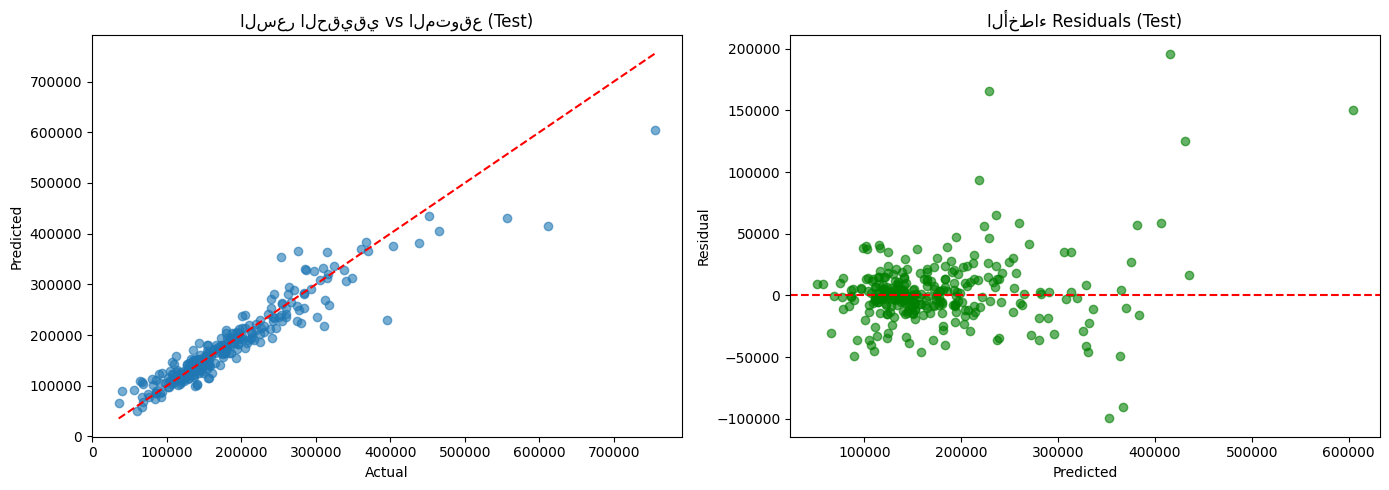

In [15]:
residuals = y_test - pred_test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, pred_test, alpha=0.6)
low, high = y_test.min(), y_test.max()
axes[0].plot([low, high], [low, high], 'r--')
axes[0].set_title('السعر الحقيقي vs المتوقع (Test)')
axes[0].set_xlabel('Actual'); axes[0].set_ylabel('Predicted')

axes[1].scatter(pred_test, residuals, alpha=0.6, color='green')
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('الأخطاء Residuals (Test)')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Residual')

plt.tight_layout()
plt.show()

## 10) فحوصات التدقيق

نتحقق برمجياً من: عدم وجود Double Log، موقع المُحدِّد قبل One-Hot، عدم اعتماد التنبؤ على باقي بيانات الاختبار، وصحة المقاييس.

In [16]:
best_pipeline = grid_search.best_estimator_
selector = best_pipeline.regressor_.named_steps['selector']

# 1) لا Double Log: التنبؤ الداخلي (قبل expm1) يجب أن يكون بمقياس log (~ 10 إلى 14)
raw_log_pred = best_pipeline.regressor_.predict(X_test)
assert 10 < raw_log_pred.min() and raw_log_pred.max() < 14
assert np.allclose(np.expm1(raw_log_pred), pred_test)
print('1) OK: الهدف يُحوَّل بـ log مرة واحدة فقط (داخل TransformedTargetRegressor)')

# 2) ترتيب الـ Pipeline: المُحدِّد أولاً (على الأعمدة الأصلية) ثم Preprocessing/OneHot
steps = list(best_pipeline.regressor_.named_steps)
assert steps == ['selector', 'preprocessing', 'model'], steps
assert len(selector.all_columns_) == 79
used_by_onehot = set(best_pipeline.regressor_.named_steps['preprocessing'].feature_names_in_)
assert used_by_onehot == set(selector.selected_columns_)
print('2) OK: الخطوات', steps, '| المُحدِّد يستقبل 79 عموداً، والـ Preprocessing يستقبل فقط', len(used_by_onehot))

# 3) لا اعتماد على باقي بيانات الاختبار: التنبؤ صفاً صفاً = التنبؤ دفعة واحدة
single = np.array([best_pipeline.predict(X_test.iloc[[i]])[0] for i in range(25)])
assert np.allclose(single, pred_test[:25])
print('3) OK: التنبؤ لا يتأثر ببقية صفوف الاختبار')

# 4) صحة المقاييس: نحسبها يدوياً ونقارنها بـ sklearn
err = y_test.values - pred_test
manual = {'R2': 1 - (err ** 2).sum() / ((y_test.values - y_test.values.mean()) ** 2).sum(),
          'RMSE': np.sqrt((err ** 2).mean()),
          'MAE': np.abs(err).mean()}
for name in ['R2', 'RMSE', 'MAE']:
    assert np.isclose(manual[name], final_results.loc['Test', name]), name
print('4) OK: R2 / RMSE / MAE اليدوية تطابق sklearn:', {k: round(v, 4) for k, v in manual.items()})

1) OK: الهدف يُحوَّل بـ log مرة واحدة فقط (داخل TransformedTargetRegressor)
2) OK: الخطوات ['selector', 'preprocessing', 'model'] | المُحدِّد يستقبل 79 عموداً، والـ Preprocessing يستقبل فقط 16
3) OK: التنبؤ لا يتأثر ببقية صفوف الاختبار
4) OK: R2 / RMSE / MAE اليدوية تطابق sklearn: {'R2': 0.8931, 'RMSE': 28639.7163, 'MAE': 16986.3579}


## 11) الأعمدة الأصلية المختارة والمستبعدة (النموذج النهائي)

قبل الاختيار: 79 عموداً | بعد الاختيار: 16 | المستبعدة: 63

الأعمدة المختارة (16):
['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars', 'GarageArea', 'BsmtFinSF1', '1stFlrSF', 'LotArea', 'CentralAir', 'YearBuilt', 'OverallCond', 'YearRemodAdd', 'BsmtQual', 'GarageType', '2ndFlrSF', 'OpenPorchSF']

الأعمدة المستبعدة (63):
['MSSubClass', 'MSZoning', 'LotFrontage', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'Heating', 'HeatingQC', 'Electrical', 'LowQualFinSF', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'Gar

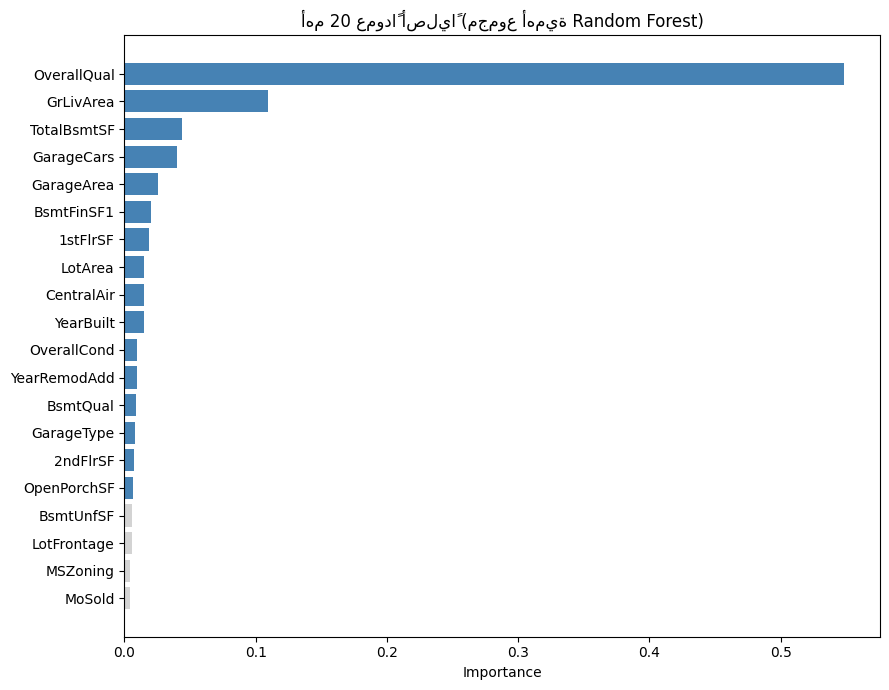

In [17]:
selected = selector.selected_columns_
excluded = [c for c in selector.all_columns_ if c not in selected]
print(f'قبل الاختيار: {len(selector.all_columns_)} عموداً | بعد الاختيار: {len(selected)} | المستبعدة: {len(excluded)}')
print(f'\nالأعمدة المختارة ({len(selected)}):')
print(selected)
print(f'\nالأعمدة المستبعدة ({len(excluded)}):')
print(excluded)

top_20 = selector.importances_.head(20).iloc[::-1]
colors = ['steelblue' if c in selected else 'lightgray' for c in top_20.index]
plt.figure(figsize=(9, 7))
plt.barh(top_20.index, top_20.values, color=colors)
plt.title('أهم 20 عموداً أصلياً (مجموع أهمية Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 12) حفظ النموذج وإعادة تحميله

> الصنف `OriginalFeatureSelector` معرَّف داخل الـ Notebook، لذلك عند تحميل النموذج في Notebook/برنامج آخر يجب تشغيل خلية تعريف الصنف أولاً.

In [18]:
MODEL_PATH = 'house_prices_best_model.joblib'
joblib.dump(best_pipeline, MODEL_PATH)

loaded_model = joblib.load(MODEL_PATH)
loaded_pred = loaded_model.predict(X_test)
assert np.allclose(loaded_pred, pred_test), 'التنبؤات بعد إعادة التحميل مختلفة!'
print('تم الحفظ وإعادة التحميل بنجاح. أول 3 تنبؤات من النموذج المُحمَّل:', loaded_pred[:3].round(0))
print('القيم الحقيقية:', y_test.values[:3])

تم الحفظ وإعادة التحميل بنجاح. أول 3 تنبؤات من النموذج المُحمَّل: [150163. 335933. 116473.]
القيم الحقيقية: [154500 325000 115000]


## 13) الملخص

In [19]:
all_row = comparison[(comparison['Model'] == best_model_name) & (comparison['Features'] == 'All 79')].iloc[0]
summary = pd.DataFrame({
    'Item': ['الأعمدة الأصلية', 'الأعمدة المختارة (النهائي)', 'أفضل نموذج', 'importance_threshold المختار',
             'CV RMSE (All 79، إعدادات افتراضية)', 'CV RMSE (Selected، إعدادات افتراضية)',
             'أفضل إعدادات', 'CV RMSE بعد الضبط', 'Test R2', 'Test RMSE', 'Test MAE'],
    'Value': [X.shape[1], len(selected), best_model_name, chosen_threshold,
              round(all_row['CV RMSE'], 2), round(chosen_row['CV RMSE'], 2),
              str(best_params), round(tuned_rmse, 2),
              round(final_results.loc['Test', 'R2'], 4),
              round(final_results.loc['Test', 'RMSE'], 2),
              round(final_results.loc['Test', 'MAE'], 2)],
})
display(summary)

,Item,Value
0,الأعمدة الأصلية,79
1,الأعمدة المختارة (النهائي),16
2,أفضل نموذج,Gradient Boosting
3,importance_threshold المختار,0.9
4,CV RMSE (All 79، إعدادات افتراضية),28570.62
5,CV RMSE (Selected، إعدادات افتراضية),29092.61
6,أفضل إعدادات,"{'regressor__model__learning_rate': 0.05, 'reg..."
7,CV RMSE بعد الضبط,28630.77
8,Test R2,0.8931
9,Test RMSE,28639.72
